In [1]:
import gym, os
from itertools import count
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.distributions import Categorical
import matplotlib.pyplot as plt
from torchsummary import summary

import numpy as np
import pandas as pd 

import torch.optim as optim
import random
import numpy as np
from collections import deque
from data_extract_65_updated import process_topology

import os
import gc

In [2]:
def find_json_file(directory):
    # Search for the first JSON file in the specified directory
    for filename in os.listdir(directory):
        if filename.endswith('.json'):
            return os.path.join(directory, filename)  # Return the full path of the first found JSON file
    return None   

In [3]:
json_directory = os.getcwd()
json_file_path = find_json_file(json_directory)
num_functions = 4  

cloud_node, regional_nodes, edge_nodes, latency = process_topology(json_file_path)

fixed_costs = np.array([5, 10, 20])

#cost for XP and ET>> CN, RN , EN            
variable_costs1 = np.array([[4,8,16],
                  [1,2,4]])

#cost for SD and DB>> CN, RN, EN 
variable_costs2 = np.array([[2,4,8],
                  [2,4,8]])

# all_coordinates = generate_coordinates()

In [4]:
print(regional_nodes)
print(edge_nodes)

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
[17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64]


In [5]:
def encode_node_types(cloud_nodes, regional_nodes, edge_nodes):
    node_type_list = []

    # Assign type encodings
    for node in cloud_nodes:
        node_type_list.append([node, 0])  # Cloud → 0
    for node in regional_nodes:
        node_type_list.append([node, 1])  # Regional → 1
    for node in edge_nodes:
        node_type_list.append([node, 2])  # Edge → 2

    # Convert to NumPy array and sort by node ID
    node_type_array = np.array(node_type_list)
    node_type_array = node_type_array[node_type_array[:, 0].argsort()]

    return node_type_array

node_encoded= encode_node_types(cloud_node, regional_nodes, edge_nodes)

print(node_encoded)

[[ 0  0]
 [ 1  1]
 [ 2  1]
 [ 3  1]
 [ 4  1]
 [ 5  1]
 [ 6  1]
 [ 7  1]
 [ 8  1]
 [ 9  1]
 [10  1]
 [11  1]
 [12  1]
 [13  1]
 [14  1]
 [15  1]
 [16  1]
 [17  2]
 [18  2]
 [19  2]
 [20  2]
 [21  2]
 [22  2]
 [23  2]
 [24  2]
 [25  2]
 [26  2]
 [27  2]
 [28  2]
 [29  2]
 [30  2]
 [31  2]
 [32  2]
 [33  2]
 [34  2]
 [35  2]
 [36  2]
 [37  2]
 [38  2]
 [39  2]
 [40  2]
 [41  2]
 [42  2]
 [43  2]
 [44  2]
 [45  2]
 [46  2]
 [47  2]
 [48  2]
 [49  2]
 [50  2]
 [51  2]
 [52  2]
 [53  2]
 [54  2]
 [55  2]
 [56  2]
 [57  2]
 [58  2]
 [59  2]
 [60  2]
 [61  2]
 [62  2]
 [63  2]
 [64  2]]


In [6]:
def compute_cost_new(action, previous_action, variable_costs):
    node_class = int(node_encoded[node_encoded[:, 0] == action, 1][0])

    # Waive the fixed cost only when this exact node has already been activated.
    if action in previous_action:
        total_cost = 0
    else:
        total_cost = fixed_costs[node_class]

    for j in range(variable_costs.shape[0]):
        total_cost += variable_costs[j, node_class]

    return total_cost



In [7]:
# Concatenate b as the first column of a
# state= np.concatenate((latency, node_cost1, node_cost2), axis=1)
state=latency.copy()
print(state.shape)

(65, 65)


In [8]:
#state

In [9]:
#k=0
#state[k,:] #represent k'th node latencys with all other nodes 

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
lr = 0.00001
gamma=0.99
random_seed= 543

In [11]:
LARGE_VALUE = 20  # High latency for masking
LATENCY_LIMIT_MS = 10.0
# Enforce total latency < 10 ms while retaining the original <= comparison.
#LATENCY_THRESHOLD_MS = np.nextafter(LATENCY_LIMIT_MS, -np.inf)


def _repeat_penalty(
    action,
    previous_action,
    base_penalty=1,
    growth_factor=5,
    max_penalty=1000.0
):
    penalty = 0.0
    repeat_count = 0

    for prev in reversed(previous_action):
        if prev == action:
            penalty += base_penalty * (
                growth_factor ** repeat_count
            )
            repeat_count += 1

            if penalty >= max_penalty:
                return max_penalty
        else:
            break

    return min(penalty, max_penalty)


# Agent 1: original reward plus the requested first-stage latency penalty.
def compute_reward1(state, action, cost_action, previous_action, variable_cost,
                    base_penalty=1, omega1=2.0, omega2=5.0,
                    omega3=2.0, omega4=1.0):
    c_total = compute_cost_new(action, cost_action, variable_cost)
    latencies = state[action, :]
    covered_latencies = latencies[latencies <= 10]
    #N_covered = len(covered_latencies)
    N_covered = np.sum(latencies <= 10)

    P_no_coverage = 1 if N_covered == 0 else 0
    P_latency = float(np.mean(covered_latencies)) if N_covered > 0 else 0.0
    P_repeat = _repeat_penalty(action, previous_action, base_penalty)

    reward = (
        omega1 / max(c_total, 1e-8)
        + omega2 * N_covered
        - omega3 * P_no_coverage 
        - omega4 * P_latency
        - P_repeat
        
    )
    return c_total, float(reward), N_covered, latencies


# Agent 2: state2 already contains E2N->G1 + G1->G2 latency.
# Therefore, no separate Agent-2 latency-minimization penalty is used.
def compute_reward2(state, action, cost_action, previous_action, variable_cost,
                    base_penalty=1, omega1=2.0, omega2=5.0,
                    omega3=2.0):
    c_total = compute_cost_new(action, cost_action, variable_cost)
    total_loop_latencies = state[action, :]
    N_covered = np.sum(total_loop_latencies <= 10)

    P_no_coverage = 1 if N_covered == 0 else 0
    P_repeat = _repeat_penalty(action, previous_action, base_penalty)

    reward = (
        omega1 / max(c_total, 1e-8)
        + omega2 * N_covered
        - omega3 * P_no_coverage
        - P_repeat
    )
    return c_total, float(reward), int(N_covered), total_loop_latencies


In [12]:
state.shape[0]//8

8

In [13]:
class Actor(nn.Module):
    def __init__(self, state_size, action_size):
        super(Actor, self).__init__()
        self.action_size = action_size
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2) 

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2) 

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2) 
        # self.conv4 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)

        
        # Calculate the flattened size after convolutions
        #self._to_linear = 64 * state_size[0] // 8 * state_size[1] // 8  # Adjust based on input dimensions
        
        self.fc1 = nn.Linear(64*(state.shape[0]//8)*(state.shape[0]//8), 1024)
        self.fc2 = nn.Linear(1024, 512)
        # self.fc3 = nn.Linear(self._to_linear, 512)
        self.fc4 = nn.Linear(512, action_size)



    def forward(self, x):
        # Add a channel dimension to 2D input (batch_size, 1, height, width)
        x = x.unsqueeze(1)  # Ensure the input is (batch_size, 1, height, width)
        
        # Apply convolutional layers with ReLU activation
        x = F.relu(self.conv1(x))
        x = self.pool1(x)
        
        x = F.relu(self.conv2(x))
        x = self.pool2(x)
        
        x = F.relu(self.conv3(x))
        x = self.pool3(x)
        
        # Flatten the output from convolutional layers
        x = x.view(x.size(0), -1)  # Flatten all dimensions except batch
        
        # # Fully connected layers
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc4(x)

        x = Categorical(F.softmax(x, dim=-1))
        
        return x



if __name__ == '__main__':
    actor = Actor([state.shape[0], state.shape[1]], state.shape[0])
    input_shape = state.shape # (channels, height, width)
    summary(actor, input_shape, device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 65, 65]             160
         MaxPool2d-2           [-1, 16, 32, 32]               0
            Conv2d-3           [-1, 32, 32, 32]           4,640
         MaxPool2d-4           [-1, 32, 16, 16]               0
            Conv2d-5           [-1, 64, 16, 16]          18,496
         MaxPool2d-6             [-1, 64, 8, 8]               0
            Linear-7                 [-1, 1024]       4,195,328
            Linear-8                  [-1, 512]         524,800
            Linear-9                   [-1, 65]          33,345
Total params: 4,776,769
Trainable params: 4,776,769
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.02
Forward/backward pass size (MB): 1.12
Params size (MB): 18.22
Estimated Total Size (MB): 19.36
-------------------------------------

In [14]:
class Critic(nn.Module):
    def __init__(self, state_size):
        super(Critic, self).__init__()

        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2) 

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2) 

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2) 
        # self.conv4 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)

        
        # Calculate the flattened size after convolutions
        self._to_linear = 64 * state_size[0] // 8 * state_size[1] // 8  # Adjust based on input dimensions
        
        self.fc1 = nn.Linear(64*(state.shape[0]//8)*(state.shape[0]//8), 512)
        self.fc2 = nn.Linear(512, 256)
        # self.fc3 = nn.Linear(self._to_linear, 512)
        self.fc4 = nn.Linear(256, 1)


    def forward(self, x):
        # Add a channel dimension to 2D input (batch_size, 1, height, width)
        x = x.unsqueeze(1)  # Ensure the input is (batch_size, 1, height, width)
        
        # Apply convolutional layers with ReLU activation
        x = F.relu(self.conv1(x))
        x = self.pool1(x)
        
        x = F.relu(self.conv2(x))
        x = self.pool2(x)
        
        x = F.relu(self.conv3(x))
        x = self.pool3(x)
        
        # Flatten the output from convolutional layers
        x = x.view(x.size(0), -1)  # Flatten all dimensions except batch
        
        # Fully connected layers
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc4(x)


        
        return x
    

if __name__ == '__main__':
    actor = Critic([state.shape[0], state.shape[0]])
    input_shape = state.shape  # (channels, height, width)
    summary(actor, input_shape, device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 65, 65]             160
         MaxPool2d-2           [-1, 16, 32, 32]               0
            Conv2d-3           [-1, 32, 32, 32]           4,640
         MaxPool2d-4           [-1, 32, 16, 16]               0
            Conv2d-5           [-1, 64, 16, 16]          18,496
         MaxPool2d-6             [-1, 64, 8, 8]               0
            Linear-7                  [-1, 512]       2,097,664
            Linear-8                  [-1, 256]         131,328
            Linear-9                    [-1, 1]             257
Total params: 2,252,545
Trainable params: 2,252,545
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.02
Forward/backward pass size (MB): 1.12
Params size (MB): 8.59
Estimated Total Size (MB): 9.72
---------------------------------------

In [15]:
# state1=state[:, edge_nodes+[-2]]
def compute_returns(next_value, rewards, masks, gamma=0.99):
    R = next_value
    returns = []
    for step in reversed(range(len(rewards))):
        R = rewards[step] + gamma * R * masks[step]
        returns.insert(0, R)
    return returns


def update_state(state, action):
    updated_state = np.copy(state)
    latency_idx=np.where(updated_state[action, :] <= 10)[0]
    updated_state[:, latency_idx] = LARGE_VALUE  # Mark selected node's latencies as high
    return updated_state

# state1.shape

In [16]:
# def trainIters(actor, critic, n_iters):
state_size=[state.shape[0], state.shape[0]]
action_size=state.shape[0]

actor1 = Actor(state_size, action_size).to(device)
critic1 = Critic(state_size).to(device)


optimizerA1 = optim.Adam(actor1.parameters(), lr=0.00001)
optimizerC1 = optim.Adam(critic1.parameters(), lr=0.00001)
avg_return1=[]
avg_a_loss1=[]
avg_c_loss1=[]

#n_iters=4000

TRAIN_EPISODES = 3600
TOTAL_EPISODES = 4000

actor2 = Actor(state_size, action_size).to(device)
critic2 = Critic(state_size).to(device)


optimizerA2 = optim.Adam(actor2.parameters(), lr=0.00001)
optimizerC2 = optim.Adam(critic2.parameters(), lr=0.00001)
avg_return2=[]
avg_a_loss2=[]
avg_c_loss2=[]
all_cost1=[]
all_cost2=[]

In [17]:
state1=state.copy() #Create a mask for columns that are NOT in edge_nodes

# print(state1)

mask = np.ones(state1.shape[1], dtype=bool)
# print(mask)
mask[edge_nodes] = False  # Set False for columns in edge_nodes
# print(mask)


# Apply LARGE_VALUE to all columns except edge_nodes
state1[:, mask] = LARGE_VALUE

print(state1)


[[20 20 20 ...  8 20 22]
 [20 20 20 ... 18 20 14]
 [20 20 20 ... 16 24 24]
 ...
 [20 20 20 ...  0 28 18]
 [20 20 20 ... 28  0 28]
 [20 20 20 ... 18 28  0]]


In [18]:
# ============================================================
# NEW BLOCK: CENTRALIZED TEAM-VALUE CRITIC (MAPPO-STYLE CTDE)
# ============================================================
# WHY:
#   The existing local critics keep the original per-step learning stable.
#   This same critic supplies one shared team advantage after both agents
#   finish the current episode. PPO then uses clipped probability ratios to
#   prevent an excessively large cooperative policy update.
# WHERE USED:
#   At the end of every joint episode for clipped PPO actor/value updates.
# INPUT:
#   A two-channel centralized observation with shape [batch, 2, N, N]:
#       channel 0 = Agent-1 initial masked state;
#       channel 1 = Agent-2 initial state conditioned on Agent-1 placement.
# OUTPUT:
#   One scalar V_team(S_joint), the expected scaled team return.
# NOTE:
#   A centralized state-value critic is consistent with MAPPO for categorical
#   policies. The selected actions affect the PPO ratio and shared team return;
#   they are therefore not concatenated directly into V_team(S_joint).
class CentralizedTeamCritic(nn.Module):
    def __init__(self, state_size):
        super(CentralizedTeamCritic, self).__init__()

        self.conv1 = nn.Conv2d(
            in_channels=2,
            out_channels=16,
            kernel_size=3,
            stride=1,
            padding=1
        )
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            stride=1,
            padding=1
        )
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv3 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            stride=1,
            padding=1
        )
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        pooled_height = state_size[0] // 8
        pooled_width = state_size[1] // 8

        self.fc1 = nn.Linear(
            64 * pooled_height * pooled_width,
            512
        )
        self.fc2 = nn.Linear(512, 256)
        self.value_output = nn.Linear(256, 1)

    def forward(self, joint_state):
        x = F.relu(self.conv1(joint_state))
        x = self.pool1(x)

        x = F.relu(self.conv2(x))
        x = self.pool2(x)

        x = F.relu(self.conv3(x))
        x = self.pool3(x)

        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))

        return self.value_output(x)


# Centralized critic configuration. Local actor/critic optimizers above remain
# unchanged. Scaling applies only to this critic and does not alter either
# agent's cost, reward, state, masking, or per-step A2C update.
# PPO is added only to the episode-level cooperative update.
# The existing per-step local A2C hyperparameters remain unchanged.
TEAM_REWARD_SCALE = 0.01
PPO_CLIP_EPSILON = 0.20
PPO_VALUE_CLIP_EPSILON = 0.20
PPO_EPOCHS = 4
PPO_ENTROPY_COEFFICIENT = 0.001
PPO_COOPERATIVE_WEIGHT = 0.05
CENTRAL_CRITIC_LR = 0.00001
MAX_CENTRAL_GRAD_NORM = 1.0

central_critic = CentralizedTeamCritic(
    [state.shape[0], state.shape[1]]
).to(device)

optimizerCentral = optim.Adam(
    central_critic.parameters(),
    lr=CENTRAL_CRITIC_LR
)

# Display a readable layer layout and verify the centralized input/output.
print("Centralized team critic layout:")
print(central_critic)

example_joint_state = torch.zeros(
    1,
    2,
    state.shape[0],
    state.shape[1],
    device=device
)

with torch.no_grad():
    example_team_value = central_critic(example_joint_state)

print("Centralized input shape:", example_joint_state.shape)
print("Centralized output shape:", example_team_value.shape)

Centralized team critic layout:
CentralizedTeamCritic(
  (conv1): Conv2d(2, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (value_output): Linear(in_features=256, out_features=1, bias=True)
)
Centralized input shape: torch.Size([1, 2, 65, 65])
Centralized output shape: torch.Size([1, 1])


In [19]:
# ============================================================
# NEW BLOCK: BUILD THE PER-EPISODE HIERARCHICAL CONTEXT
# ============================================================
# WHY:
#   Agent 2 must train in the same episode using the G1 locations selected by
#   Agent 1 in that episode. Early exploratory Agent-1 episodes may cover only
#   part of the E2 set, so training mode keeps the feasible covered subset
#   instead of stopping all training with a RuntimeError.
# WHERE USED:
#   Immediately after the Agent-1 rollout and once after all training for the
#   final strict feasibility check.
# INPUT:
#   Agent-1 action history and require_complete flag.
# OUTPUT:
#   The original Agent-2 state2 and all G1/E2 association dictionaries.
def build_agent2_context(agent1_nodes, require_complete=False):
    learned_g1_nodes = np.unique(
        np.asarray(agent1_nodes, dtype=int)
    )

    if learned_g1_nodes.size == 0:
        if require_complete:
            raise RuntimeError("Agent 1 did not select any G1 node.")

        empty_state2 = np.full_like(
            state,
            LARGE_VALUE,
            dtype=float
        )

        return (
            empty_state2,
            learned_g1_nodes,
            {},
            {},
            {},
            np.array([], dtype=int),
            {}
        )

    e2_to_g1_local = {}
    agent1_latency_local = {}

    for e2_node in edge_nodes:
        feasible_g1_nodes = [
            int(g1_node)
            for g1_node in learned_g1_nodes
            if latency[int(g1_node), int(e2_node)] <= LATENCY_LIMIT_MS
        ]

        if not feasible_g1_nodes:
            if require_complete:
                lowest_latency = min(
                    float(latency[int(g1_node), int(e2_node)])
                    for g1_node in learned_g1_nodes
                )
                raise RuntimeError(
                    f"Agent 1 did not learn a feasible G1 location for "
                    f"E2 node {e2_node}. Lowest learned latency is "
                    f"{lowest_latency:.3f} ms."
                )
            continue

        selected_g1 = min(
            feasible_g1_nodes,
            key=lambda g1_node: latency[
                int(g1_node), int(e2_node)
            ]
        )

        first_stage_latency = float(
            latency[int(selected_g1), int(e2_node)]
        )

        e2_to_g1_local[int(e2_node)] = int(selected_g1)
        agent1_latency_local[int(e2_node)] = first_stage_latency

    g1_to_e2_local = {}
    for e2_node, g1_node in e2_to_g1_local.items():
        g1_to_e2_local.setdefault(g1_node, []).append(e2_node)

    active_g1_local = np.array(
        sorted(g1_to_e2_local.keys()),
        dtype=int
    )

    g1_first_latency_local = {
        g1_node: max(
            agent1_latency_local[e2_node]
            for e2_node in assigned_e2_nodes
        )
        for g1_node, assigned_e2_nodes in g1_to_e2_local.items()
    }

    state2_local = np.full_like(
        state,
        LARGE_VALUE,
        dtype=float
    )

    for g1_node in active_g1_local:
        state2_local[:, g1_node] = (
            latency[:, g1_node]
            + g1_first_latency_local[int(g1_node)]
        )

    return (
        state2_local,
        learned_g1_nodes,
        e2_to_g1_local,
        agent1_latency_local,
        g1_to_e2_local,
        active_g1_local,
        g1_first_latency_local
    )


# ============================================================
# NEW PPO BLOCK: CENTRALIZED OBSERVATION AND CLIPPED ACTOR LOSS
# ============================================================
# WHY:
#   PPO compares the current categorical policy with the behavior policy that
#   selected each stored action. Clipping the probability ratio limits the
#   additional cooperative update while retaining every original local update.
# WHERE USED:
#   After both agents finish the current episode, for PPO_EPOCHS passes.
# INPUT:
#   Joint initial states, each actor's saved state/action trajectory, stored old
#   log-probabilities, and the shared centralized team advantage.
# OUTPUT:
#   A normalized [1, 2, N, N] centralized state and one clipped PPO actor loss.
def build_centralized_state(agent1_state, agent2_state):
    joint_state = np.stack(
        (
            np.asarray(agent1_state, dtype=np.float32),
            np.asarray(agent2_state, dtype=np.float32)
        ),
        axis=0
    )

    joint_state = joint_state / max(float(LARGE_VALUE), 1.0)

    return torch.as_tensor(
        joint_state,
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)


def compute_clipped_ppo_actor_loss(
    actor,
    saved_states,
    saved_actions,
    old_log_probabilities,
    team_advantage
):
    if len(saved_actions) == 0:
        return None, 0.0, 0.0

    current_log_probabilities = []
    current_entropies = []

    for saved_state, saved_action in zip(
        saved_states,
        saved_actions
    ):
        saved_state_tensor = torch.as_tensor(
            saved_state,
            dtype=torch.float32,
            device=device
        ).unsqueeze(0)

        current_distribution = actor(saved_state_tensor)
        saved_action_tensor = torch.tensor(
            [saved_action],
            dtype=torch.long,
            device=device
        )

        current_log_probabilities.append(
            current_distribution.log_prob(saved_action_tensor).mean()
        )
        current_entropies.append(
            current_distribution.entropy().mean()
        )

    current_log_probabilities = torch.stack(
        current_log_probabilities
    )
    current_entropies = torch.stack(current_entropies)

    old_log_probabilities_tensor = torch.as_tensor(
        old_log_probabilities,
        dtype=torch.float32,
        device=device
    )

    probability_ratio = torch.exp(
        current_log_probabilities
        - old_log_probabilities_tensor
    )

    shared_advantage = team_advantage.detach().reshape(1)
    unclipped_surrogate = probability_ratio * shared_advantage
    clipped_surrogate = torch.clamp(
        probability_ratio,
        1.0 - PPO_CLIP_EPSILON,
        1.0 + PPO_CLIP_EPSILON
    ) * shared_advantage

    policy_loss = -torch.min(
        unclipped_surrogate,
        clipped_surrogate
    ).mean()

    entropy_bonus = current_entropies.mean()
    total_ppo_actor_loss = (
        PPO_COOPERATIVE_WEIGHT * policy_loss
        - PPO_ENTROPY_COEFFICIENT * entropy_bonus
    )

    clip_fraction = (
        (torch.abs(probability_ratio - 1.0) > PPO_CLIP_EPSILON)
        .float()
        .mean()
        .item()
    )

    return (
        total_ppo_actor_loss,
        float(probability_ratio.mean().item()),
        float(clip_fraction)
    )


# Histories used only for reporting/plotting the cooperative training run.
team_return_history = []
central_critic_loss_history = []

In [20]:
# ============================================================
# REPLACEMENT TRAINING BLOCK: HIERARCHICAL COOPERATIVE MAPPO V1
# ============================================================
# WHY:
#   Both agents now act and learn in every episode. Each keeps the original
#   V5 per-step local Critic/Actor loss, backward(), and optimizer.step().
#   After both rollouts, a centralized team advantage drives clipped PPO
#   updates for both actors and a clipped centralized-value update.
# WHERE USED:
#   Replaces the two fully separate Agent-1-then-Agent-2 training loops.
# INPUT:
#   Existing state1, cost/reward/update_state functions, Actor/Critic models,
#   optimizers, latency matrix, and node sets. These are not redefined here.
# OUTPUT:
#   The same per-agent reward/cost/actor-loss histories and final placements,
#   plus internal team-return and PPO central-critic-loss histories.
for iter in range(1, TOTAL_EPISODES + 1):
    print(f"Episode {iter} starts")

    # --------------------------------------------------------
    # AGENT 1 ROLLOUT: original per-step local A2C flow
    # --------------------------------------------------------
    state_n1 = state1.copy()
    selected_nodes1 = []
    previous_action1 = []
    agent1_saved_states = []
    agent1_old_log_probabilities = []

    episode_reward1 = 0.0
    episode_cost1 = 0.0
    episode_a_loss1 = 0.0
    episode_c_loss1 = 0.0

    done1 = False
    actor_loss1 = torch.tensor(0.0, device=device)
    critic_loss1 = torch.tensor(0.0, device=device)

    for i in range(200):
        state_tensor1 = torch.FloatTensor(
            state_n1
        ).unsqueeze(0).to(device)

        dist1 = actor1(state_tensor1)
        value1 = critic1(state_tensor1)

        # Preserve the original Agent-1 exploration/exploitation rule.
        if iter <= TRAIN_EPISODES:
            action1 = dist1.sample()
        else:
            feasible_action_mask1 = np.any(
                state_n1[:, edge_nodes] <= 10.0,
                axis=1
            )

            feasible_actions1 = np.where(
                feasible_action_mask1
            )[0]

            if feasible_actions1.size == 0:
                break

            action_probabilities1 = dist1.probs.squeeze(0)
            masked_probabilities1 = torch.full_like(
                action_probabilities1,
                -torch.inf
            )

            feasible_actions_tensor1 = torch.tensor(
                feasible_actions1,
                dtype=torch.long,
                device=device
            )

            masked_probabilities1[feasible_actions_tensor1] = (
                action_probabilities1[feasible_actions_tensor1]
            )

            action1 = torch.argmax(
                masked_probabilities1
            ).view(1)

        action1_id = int(action1.item())
        agent1_saved_states.append(state_n1.copy())
        selected_nodes1.append(action1_id)

        next_state1 = update_state(
            state_n1,
            action1_id
        )

        cost1, reward1, n_cov1, lat1 = compute_reward1(
            state_n1,
            action1_id,
            previous_action1,
            previous_action1,
            variable_costs1
        )

        done1 = np.all(
            next_state1[:, edge_nodes] == LARGE_VALUE
        )

        previous_action1.append(action1_id)

        next_value1 = critic1(
            torch.FloatTensor(next_state1).unsqueeze(0).to(device)
        )

        # Original one-step local Critic-1 target and loss.
        td_target1 = reward1 + gamma * next_value1 * (1 - done1)
        advantage1 = td_target1 - value1
        critic_loss1 = F.mse_loss(
            value1,
            td_target1.detach()
        )

        episode_c_loss1 += critic_loss1.item()

        # Original per-step local Critic-1 update.
        if iter <= TRAIN_EPISODES:
            optimizerC1.zero_grad()
            critic_loss1.backward()
            optimizerC1.step()

        # Original one-step local Actor-1 loss and per-step update.
        log_prob1 = dist1.log_prob(action1)
        # PPO behavior probability is stored before this local update.
        agent1_old_log_probabilities.append(
            float(log_prob1.detach().mean().item())
        )
        actor_loss1 = -log_prob1 * advantage1.detach()
        episode_a_loss1 += actor_loss1.item()

        if iter <= TRAIN_EPISODES:
            optimizerA1.zero_grad()
            actor_loss1.backward()
            optimizerA1.step()
            torch.nn.utils.clip_grad_norm_(
                actor1.parameters(),
                max_norm=1.0
            )

        episode_reward1 += reward1
        episode_cost1 += cost1
        state_n1 = next_state1.copy()

        if done1:
            break

    # --------------------------------------------------------
    # BUILD AGENT-2 STATE FROM THIS EPISODE'S AGENT-1 ACTIONS
    # --------------------------------------------------------
    (
        state2_episode,
        agent1_activated_nodes_episode,
        e2_to_g1_episode,
        agent1_selected_latency_episode,
        g1_to_e2_episode,
        active_g1_nodes_episode,
        g1_first_stage_latency_episode
    ) = build_agent2_context(
        selected_nodes1,
        require_complete=False
    )

    # --------------------------------------------------------
    # AGENT 2 ROLLOUT: original stochastic per-step local A2C
    # --------------------------------------------------------
    state_n2 = state2_episode.copy()
    selected_nodes2 = []
    previous_action2 = []
    agent2_saved_states = []
    agent2_old_log_probabilities = []

    episode_reward2 = 0.0
    episode_cost2 = 0.0
    episode_a_loss2 = 0.0
    episode_c_loss2 = 0.0

    done2 = active_g1_nodes_episode.size == 0
    actor_loss2 = torch.tensor(0.0, device=device)
    critic_loss2 = torch.tensor(0.0, device=device)

    if not done2:
        for i in range(200):
            state_tensor2 = torch.FloatTensor(
                state_n2
            ).unsqueeze(0).to(device)

            dist2 = actor2(state_tensor2)
            value2 = critic2(state_tensor2)

            # Preserve the original Agent-2 rule: stochastic sampling in
            # every episode, with no added feasible-action mask or freeze.
            action2 = dist2.sample()
            action2_id = int(action2.item())

            agent2_saved_states.append(state_n2.copy())
            selected_nodes2.append(action2_id)

            next_state2 = update_state(
                state_n2,
                action2_id
            )

            # Preserve the original cost logic: G1 nodes and earlier G2 nodes
            # are already active and therefore do not pay fixed cost again.
            cost_action2 = (
                list(agent1_activated_nodes_episode)
                + list(previous_action2)
            )

            cost2, reward2, n_cov2, lat2 = compute_reward2(
                state_n2,
                action2_id,
                cost_action2,
                previous_action2,
                variable_costs2
            )

            done2 = np.all(
                next_state2[:, active_g1_nodes_episode]
                == LARGE_VALUE
            )

            previous_action2.append(action2_id)

            next_value2 = critic2(
                torch.FloatTensor(next_state2).unsqueeze(0).to(device)
            )

            # Original one-step local Critic-2 target and per-step update.
            td_target2 = reward2 + gamma * next_value2 * (1 - done2)
            advantage2 = td_target2 - value2
            critic_loss2 = F.mse_loss(
                value2,
                td_target2.detach()
            )

            episode_c_loss2 += critic_loss2.item()

            optimizerC2.zero_grad()
            critic_loss2.backward()
            optimizerC2.step()

            # Original one-step local Actor-2 loss and per-step update.
            log_prob2 = dist2.log_prob(action2)
            # PPO behavior probability is stored before this local update.
            agent2_old_log_probabilities.append(
                float(log_prob2.detach().mean().item())
            )
            actor_loss2 = -log_prob2 * advantage2.detach()
            episode_a_loss2 += actor_loss2.item()

            optimizerA2.zero_grad()
            actor_loss2.backward()
            optimizerA2.step()
            torch.nn.utils.clip_grad_norm_(
                actor2.parameters(),
                max_norm=1.0
            )

            episode_reward2 += reward2
            episode_cost2 += cost2
            state_n2 = next_state2.copy()

            if done2:
                break

    # --------------------------------------------------------
    # PPO ENHANCEMENT: CENTRAL TEAM VALUE + CLIPPED ACTOR UPDATE
    # --------------------------------------------------------
    # WHY:
    #   The local per-step A2C updates above are unchanged. This additional
    #   episode-level PPO phase constrains the cooperative policy change using
    #   old/new categorical probability ratios.
    # INPUT:
    #   Raw team return, joint state, stored trajectories, and behavior-policy
    #   log-probabilities collected before each original local actor update.
    # OUTPUT:
    #   A clipped centralized value loss and clipped cooperative actor losses.
    team_return = episode_reward1 + episode_reward2
    scaled_team_target = torch.tensor(
        [[team_return * TEAM_REWARD_SCALE]],
        dtype=torch.float32,
        device=device
    )

    joint_state_tensor = build_centralized_state(
        state1,
        state2_episode
    )

    # Snapshot the pre-PPO centralized value. PPO value clipping measures all
    # central-critic changes relative to this fixed prediction.
    with torch.no_grad():
        old_team_value = central_critic(
            joint_state_tensor
        ).detach()

    team_advantage = scaled_team_target - old_team_value

    ppo_central_losses = []
    ppo_actor_losses1 = []
    ppo_actor_losses2 = []
    ppo_clip_fractions1 = []
    ppo_clip_fractions2 = []

    for ppo_epoch in range(PPO_EPOCHS):
        # PPO-style clipped centralized value update.
        current_team_value = central_critic(joint_state_tensor)
        clipped_team_value = old_team_value + torch.clamp(
            current_team_value - old_team_value,
            -PPO_VALUE_CLIP_EPSILON,
            PPO_VALUE_CLIP_EPSILON
        )

        value_loss_unclipped = (
            current_team_value - scaled_team_target
        ).pow(2)
        value_loss_clipped = (
            clipped_team_value - scaled_team_target
        ).pow(2)

        central_critic_loss = 0.5 * torch.max(
            value_loss_unclipped,
            value_loss_clipped
        ).mean()

        optimizerCentral.zero_grad()
        central_critic_loss.backward()
        torch.nn.utils.clip_grad_norm_(
            central_critic.parameters(),
            max_norm=MAX_CENTRAL_GRAD_NORM
        )
        optimizerCentral.step()
        ppo_central_losses.append(central_critic_loss.item())

        # Agent 1 keeps its original freeze after TRAIN_EPISODES.
        if iter <= TRAIN_EPISODES:
            ppo_actor_loss1, ratio1, clip_fraction1 = (
                compute_clipped_ppo_actor_loss(
                    actor1,
                    agent1_saved_states,
                    selected_nodes1,
                    agent1_old_log_probabilities,
                    team_advantage
                )
            )

            if ppo_actor_loss1 is not None:
                optimizerA1.zero_grad()
                ppo_actor_loss1.backward()
                torch.nn.utils.clip_grad_norm_(
                    actor1.parameters(),
                    max_norm=1.0
                )
                optimizerA1.step()

                ppo_actor_losses1.append(
                    ppo_actor_loss1.item()
                )
                ppo_clip_fractions1.append(clip_fraction1)

        # Agent 2 remains stochastic and trainable in every episode.
        ppo_actor_loss2, ratio2, clip_fraction2 = (
            compute_clipped_ppo_actor_loss(
                actor2,
                agent2_saved_states,
                selected_nodes2,
                agent2_old_log_probabilities,
                team_advantage
            )
        )

        if ppo_actor_loss2 is not None:
            optimizerA2.zero_grad()
            ppo_actor_loss2.backward()
            torch.nn.utils.clip_grad_norm_(
                actor2.parameters(),
                max_norm=1.0
            )
            optimizerA2.step()

            ppo_actor_losses2.append(ppo_actor_loss2.item())
            ppo_clip_fractions2.append(clip_fraction2)

    central_critic_loss_value = float(
        np.mean(ppo_central_losses)
    )
    cooperative_actor_loss1_value = float(
        np.mean(ppo_actor_losses1)
    ) if ppo_actor_losses1 else 0.0
    cooperative_actor_loss2_value = float(
        np.mean(ppo_actor_losses2)
    ) if ppo_actor_losses2 else 0.0

    # Store one value per episode. Actor-loss histories include both the
    # original local per-step losses and the new cooperative actor loss.
    avg_return1.append(episode_reward1)
    avg_return2.append(episode_reward2)
    all_cost1.append(episode_cost1)
    all_cost2.append(episode_cost2)

    avg_a_loss1.append(
        episode_a_loss1 + cooperative_actor_loss1_value
    )
    avg_a_loss2.append(
        episode_a_loss2 + cooperative_actor_loss2_value
    )
    avg_c_loss1.append(episode_c_loss1)
    avg_c_loss2.append(episode_c_loss2)

    team_return_history.append(team_return)
    central_critic_loss_history.append(
        central_critic_loss_value
    )

    agent1_phase = (
        "exploration/training"
        if iter <= TRAIN_EPISODES
        else "exploitation/frozen"
    )

    print(
        f"Episode {iter} | "
        f"Agent 1 [{agent1_phase}] "
        f"Actor Loss: {avg_a_loss1[-1]:.4f}, "
        f"Critic Loss: {avg_c_loss1[-1]:.4f}, "
        f"Return: {avg_return1[-1]}, "
        f"Cost: {all_cost1[-1]}, "
        f"Nodes: {selected_nodes1} | "
        f"Agent 2 [sampling/training] "
        f"Actor Loss: {avg_a_loss2[-1]:.4f}, "
        f"Critic Loss: {avg_c_loss2[-1]:.4f}, "
        f"Return: {avg_return2[-1]}, "
        f"Cost: {all_cost2[-1]}, "
        f"Nodes: {selected_nodes2} | "
        f"Team Return: {team_return:.4f}"
    )

Episode 1 starts
Episode 1 | Agent 1 [exploration/training] Actor Loss: -335.0083, Critic Loss: 2177.5693, Return: -85.0666666666669, Cost: 3685.0, Nodes: [36, 60, 40, 40, 33, 48, 31, 30, 56, 27, 60, 6, 18, 4, 62, 29, 45, 18, 60, 45, 19, 23, 63, 59, 16, 2, 38, 61, 62, 22, 19, 64, 7, 3, 20, 46, 21, 50, 2, 9, 7, 42, 21, 59, 32, 48, 3, 18, 32, 20, 18, 60, 41, 57, 60, 56, 2, 31, 1, 29, 25, 51, 27, 46, 17, 38, 16, 62, 9, 34, 48, 39, 1, 30, 52, 57, 61, 46, 54, 20, 21, 44, 16, 58, 61, 0, 38, 26, 22, 33, 60, 6, 7, 35, 30, 33, 25, 15, 30, 0, 55, 54, 31, 6, 6, 13, 47, 22, 3, 64, 9, 63, 63, 31, 49, 44, 33, 19, 21, 47, 7, 26, 53, 55, 33, 30, 15, 40, 2, 38, 17, 11, 38, 58, 62, 37, 18, 46, 48, 58, 36, 32, 32, 40, 8, 12, 63, 43] | Agent 2 [sampling/training] Actor Loss: -398.6157, Critic Loss: 6587.7544, Return: -93.55555555555556, Cost: 2782.0, Nodes: [11, 6, 4, 49, 9, 34, 1, 9, 2, 56, 13, 42, 43, 34, 61, 30, 41, 52, 55, 5, 29, 59, 43, 59, 28, 1, 16, 59, 39, 41, 13, 15, 22, 3, 2, 59, 33, 10, 22, 1, 

In [21]:
# ============================================================
# NEW BLOCK: REBUILD THE STRICT FINAL HIERARCHICAL CONTEXT
# ============================================================
# WHY:
#   Training permits partial exploratory Agent-1 coverage so learning is not
#   interrupted. Final reporting must instead require every E2 node to have a
#   feasible learned G1 placement before checking the complete loops.
# WHERE USED:
#   Immediately before the unchanged final G1-to-G2 association/verification.
# INPUT:
#   Final Agent-1 and Agent-2 action histories from the last joint episode.
# OUTPUT:
#   Final state2 and association variables expected by the result block below.
(
    state2,
    agent1_activated_nodes,
    e2_to_g1,
    agent1_selected_latency,
    g1_to_e2,
    active_g1_nodes,
    g1_first_stage_latency
) = build_agent2_context(
    selected_nodes1,
    require_complete=True
)

selected_nodes1 = np.unique(
    np.asarray(selected_nodes1, dtype=int)
)

selected_nodes2 = np.unique(
    np.asarray(selected_nodes2, dtype=int)
)

if selected_nodes2.size == 0:
    raise RuntimeError("Agent 2 did not select any placement node.")

print("Final Agent 1 learned nodes:", selected_nodes1)
print("Final active G1 nodes:", active_g1_nodes)
print("Final Agent 2 learned nodes:", selected_nodes2)

Final Agent 1 learned nodes: [ 0  1  9 11 12 19 23 27 30 31 36 37 38 39 43 48 56 58 63 64]
Final active G1 nodes: [ 0  1  9 11 12 19 23 27 30 31 36 37 38 39 43 48 56 58 63 64]
Final Agent 2 learned nodes: [ 0  2  3  4 11 15 19 23 24 27 31 38 43 48 52 56 58 63]


In [22]:
LATENCY_TOLERANCE_MS = 1e-9


def is_latency_feasible(latency_value):
    """Accept latency below or numerically equal to 10 ms."""
    return bool(
        latency_value <= LATENCY_LIMIT_MS
        or np.isclose(
            latency_value,
            LATENCY_LIMIT_MS,
            rtol=0.0,
            atol=LATENCY_TOLERANCE_MS
        )
    )


selected_nodes2 = np.unique(
    np.asarray(selected_nodes2, dtype=int)
)


# Associate every active G1 node with a feasible learned G2 node
# having the lowest complete-loop latency.
g1_to_g2 = {}

for g1_node in active_g1_nodes:
    g1_node = int(g1_node)

    feasible_g2_nodes = []

    for g2_node in selected_nodes2:
        g2_node = int(g2_node)

        worst_total_latency = (
            float(g1_first_stage_latency[g1_node])
            + float(latency[g2_node, g1_node])
        )

        if is_latency_feasible(worst_total_latency):
            feasible_g2_nodes.append(g2_node)

    if not feasible_g2_nodes:
        raise RuntimeError(
            f"Agent 2 did not learn a feasible G2 node for "
            f"G1 node {g1_node} under the <= 10 ms limit."
        )

    selected_g2 = min(
        feasible_g2_nodes,
        key=lambda g2_node: (
            float(g1_first_stage_latency[g1_node])
            + float(latency[g2_node, g1_node])
        )
    )

    g1_to_g2[g1_node] = int(selected_g2)


# Verify every individual E2N-to-G1-to-G2 loop.
loop_results = []

for e2_node in edge_nodes:
    e2_node = int(e2_node)
    g1_node = int(e2_to_g1[e2_node])
    g2_node = int(g1_to_g2[g1_node])

    first_latency = float(
        agent1_selected_latency[e2_node]
    )

    # Use the same G2-row, G1-column orientation used in state2.
    second_latency = float(
        latency[g2_node, g1_node]
    )

    total_latency = first_latency + second_latency
    feasible = is_latency_feasible(total_latency)

    loop_results.append({
        "E2_node": e2_node,
        "G1_node": g1_node,
        "G2_node": g2_node,
        "E2_to_G1_ms": first_latency,
        "G1_to_G2_ms": second_latency,
        "total_loop_ms": total_latency,
        "latency_at_most_10ms": feasible,
    })


loop_results = pd.DataFrame(loop_results)
display(loop_results)


if not loop_results["latency_at_most_10ms"].all():
    infeasible_loops = loop_results[
        ~loop_results["latency_at_most_10ms"]
    ]

    display(infeasible_loops)

    raise RuntimeError(
        "At least one learned E2N-to-G1-to-G2 loop has "
        "total latency greater than 10 ms."
    )


print("Agent 1 selected nodes:", selected_nodes1)
print("Agent 2 selected nodes:", selected_nodes2)
print("Final G1-to-G2 association:", g1_to_g2)
print(
    "Maximum complete-loop latency:",
    loop_results["total_loop_ms"].max(),
    "ms"
)
print("All learned complete-loop latencies are <= 10 ms.")

,E2_node,G1_node,G2_node,E2_to_G1_ms,G1_to_G2_ms,total_loop_ms,latency_at_most_10ms
0,17,9,0,2.0,2.0,4.0,True
1,18,1,24,8.0,2.0,10.0,True
2,19,19,19,0.0,0.0,0.0,True
3,20,0,0,10.0,0.0,10.0,True
4,21,9,0,2.0,2.0,4.0,True
5,22,0,0,8.0,0.0,8.0,True
6,23,23,23,0.0,0.0,0.0,True
7,24,1,24,2.0,2.0,4.0,True
8,25,0,0,10.0,0.0,10.0,True
9,26,11,11,4.0,0.0,4.0,True


Agent 1 selected nodes: [ 0  1  9 11 12 19 23 27 30 31 36 37 38 39 43 48 56 58 63 64]
Agent 2 selected nodes: [ 0  2  3  4 11 15 19 23 24 27 31 38 43 48 52 56 58 63]
Final G1-to-G2 association: {0: 0, 1: 24, 9: 0, 11: 11, 12: 0, 19: 19, 23: 23, 27: 27, 30: 2, 31: 31, 36: 3, 37: 52, 38: 38, 39: 4, 43: 43, 48: 48, 56: 56, 58: 58, 63: 63, 64: 15}
Maximum complete-loop latency: 10.0 ms
All learned complete-loop latencies are <= 10 ms.


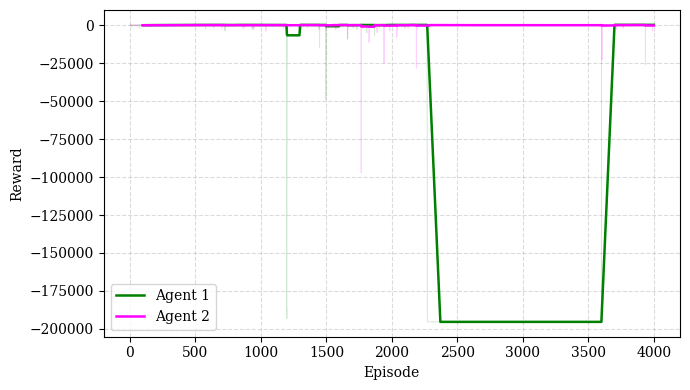

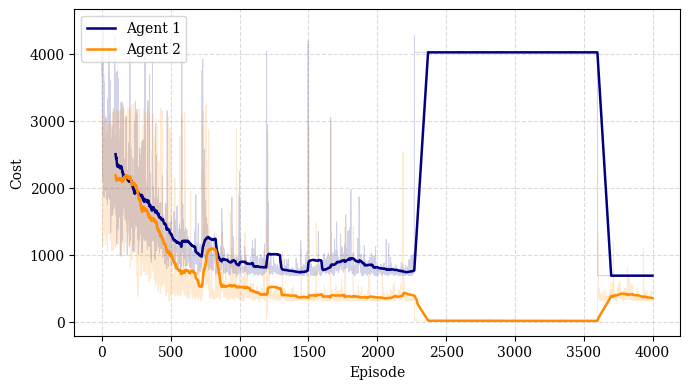

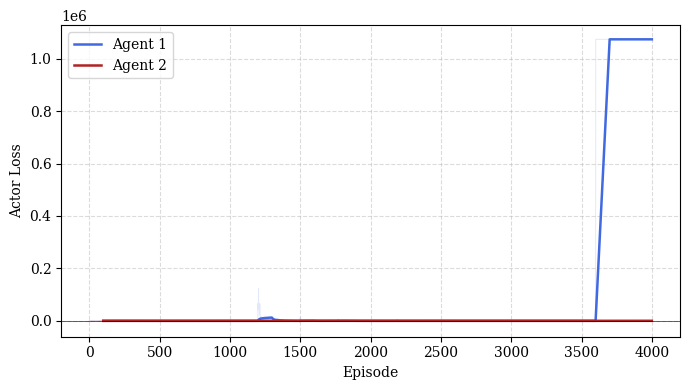

In [23]:
# ============================================================
# FINAL PLOTS: ONLY REWARD, COST, AND ACTOR LOSS
# ============================================================
# WHY:
#   These are the three requested convergence views; no central-critic or
#   diagnostic figures are produced.
# WHERE USED:
#   Run after training and final feasibility verification.
# INPUT:
#   Per-episode histories filled by the joint training loop.
# OUTPUT:
#   Exactly three figures, each comparing Agent 1 and Agent 2.
def moving_average(values, window=100):
    values = np.asarray(values, dtype=float)

    if values.size < window:
        return np.arange(values.size), values

    kernel = np.ones(window, dtype=float) / window
    smoothed = np.convolve(values, kernel, mode="valid")
    episodes = np.arange(window - 1, values.size)

    return episodes, smoothed


plt.rcParams["font.family"] = "serif"

# Figure 1: reward convergence for both agents.
plt.figure(figsize=(7.0, 4.0))
plt.plot(avg_return1, color="green", alpha=0.18, linewidth=0.7)
plt.plot(avg_return2, color="magenta", alpha=0.18, linewidth=0.7)

reward_x1, reward_ma1 = moving_average(avg_return1)
reward_x2, reward_ma2 = moving_average(avg_return2)
plt.plot(reward_x1, reward_ma1, color="green", linewidth=1.8, label="Agent 1")
plt.plot(reward_x2, reward_ma2, color="magenta", linewidth=1.8, label="Agent 2")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.grid(True, linestyle="--", alpha=0.45)
plt.legend()
plt.tight_layout()
plt.show()

# Figure 2: placement-cost convergence for both agents.
plt.figure(figsize=(7.0, 4.0))
plt.plot(all_cost1, color="navy", alpha=0.18, linewidth=0.7)
plt.plot(all_cost2, color="darkorange", alpha=0.18, linewidth=0.7)

cost_x1, cost_ma1 = moving_average(all_cost1)
cost_x2, cost_ma2 = moving_average(all_cost2)
plt.plot(cost_x1, cost_ma1, color="navy", linewidth=1.8, label="Agent 1")
plt.plot(cost_x2, cost_ma2, color="darkorange", linewidth=1.8, label="Agent 2")
plt.xlabel("Episode")
plt.ylabel("Cost")
plt.grid(True, linestyle="--", alpha=0.45)
plt.legend()
plt.tight_layout()
plt.show()

# Figure 3: clearly formatted total actor loss (local A2C + cooperative PPO feedback).
plt.figure(figsize=(7.0, 4.0))
plt.plot(avg_a_loss1, color="royalblue", alpha=0.15, linewidth=0.7)
plt.plot(avg_a_loss2, color="firebrick", alpha=0.15, linewidth=0.7)

loss_x1, loss_ma1 = moving_average(avg_a_loss1)
loss_x2, loss_ma2 = moving_average(avg_a_loss2)
plt.plot(loss_x1, loss_ma1, color="royalblue", linewidth=1.8, label="Agent 1")
plt.plot(loss_x2, loss_ma2, color="firebrick", linewidth=1.8, label="Agent 2")
plt.axhline(0.0, color="black", linewidth=0.7, alpha=0.6)
plt.xlabel("Episode")
plt.ylabel("Actor Loss")
plt.grid(True, linestyle="--", alpha=0.45)
plt.legend()
plt.tight_layout()
plt.show()